# 1. Importation des bibliothèques

Dans cette première étape, nous importons les bibliothèques nécessaires
pour effectuer l'analyse exploratoire, le prétraitement, l'entraînement
des modèles de machine learning et l'évaluation de leurs performances.

Nous utilisons principalement pandas pour manipuler les données,
NumPy pour les opérations numériques, Matplotlib pour les visualisations
et scikit-learn pour construire les modèles.

In [2]:
# Manipulation des données
import pandas as pd
import numpy as np

# Visualisation
import matplotlib.pyplot as plt

# Gestion des avertissements
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

# Séparation des données
from sklearn.model_selection import train_test_split

# Prétraitement
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

# Modèles de classification
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# Évaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

# Importance des variables
from sklearn.inspection import permutation_importance

# Gestion du modèle
import joblib

# Version de scikit-learn
import sklearn

print("Version de pandas :", pd.__version__)
print("Version de NumPy :", np.__version__)
print("Version de scikit-learn :", sklearn.__version__)

Version de pandas : 2.3.3
Version de NumPy : 2.3.5
Version de scikit-learn : 1.8.0


# 2. Chargement des données

Nous chargeons le dataset ShopExpress avec pandas.

Nous affichons ensuite les premières lignes afin de vérifier
que le fichier a été correctement importé.

In [3]:
df = pd.read_csv("shop.csv")

print("Dimensions du dataset :", df.shape)

print("Nombre de lignes :", df.shape[0])
print("Nombre de colonnes :", df.shape[1])

display(df.head())

Dimensions du dataset : (10999, 18)
Nombre de lignes : 10999
Nombre de colonnes : 18


,ID,Warehouse_block,Mode_of_Shipment,Customer_care_calls,Customer_rating,Cost_of_the_Product,Prior_purchases,Product_importance,Gender,Discount_offered,Weight_in_gms,Reached.on.Time_Y.N,Distance_km,Weather_Condition,Traffic_Level,Route_Complexity,Customer_Country,Product_Category
0,1,D,Flight,4,2,177,3,low,F,44,1233,1,3741,Clear,Non applicable,Moderate,Australia,Electronics
1,2,F,Flight,4,5,216,2,low,M,59,3088,1,2501,Rain,Non applicable,Moderate,India,Automotive Accessories
2,3,A,Flight,2,2,183,4,low,M,48,3374,1,3414,Rain,Non applicable,Moderate,Japan,Books & Stationery
3,4,B,Flight,3,3,176,4,medium,M,10,1177,1,4004,Rain,Non applicable,Moderate,United Kingdom,Beauty & Personal Care
4,5,C,Flight,2,2,184,3,medium,F,46,2484,1,970,Rain,Non applicable,Moderate,Canada,Beauty & Personal Care


In [4]:
print(df.columns.tolist())

['ID', 'Warehouse_block', 'Mode_of_Shipment', 'Customer_care_calls', 'Customer_rating', 'Cost_of_the_Product', 'Prior_purchases', 'Product_importance', 'Gender', 'Discount_offered', 'Weight_in_gms', 'Reached.on.Time_Y.N', 'Distance_km', 'Weather_Condition', 'Traffic_Level', 'Route_Complexity', 'Customer_Country', 'Product_Category']


# 3. Analyse exploratoire des données — EDA

L'analyse exploratoire permet de comprendre la structure du dataset,
de détecter les problèmes de qualité et d'identifier les caractéristiques
qui pourraient être utiles pour la prédiction du risque de retard.

In [5]:
# Informations générales
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10999 entries, 0 to 10998
Data columns (total 18 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   ID                   10999 non-null  int64 
 1   Warehouse_block      10999 non-null  object
 2   Mode_of_Shipment     10999 non-null  object
 3   Customer_care_calls  10999 non-null  int64 
 4   Customer_rating      10999 non-null  int64 
 5   Cost_of_the_Product  10999 non-null  int64 
 6   Prior_purchases      10999 non-null  int64 
 7   Product_importance   10999 non-null  object
 8   Gender               10999 non-null  object
 9   Discount_offered     10999 non-null  int64 
 10  Weight_in_gms        10999 non-null  int64 
 11  Reached.on.Time_Y.N  10999 non-null  int64 
 12  Distance_km          10999 non-null  int64 
 13  Weather_Condition    10999 non-null  object
 14  Traffic_Level        10999 non-null  object
 15  Route_Complexity     10999 non-null  object
 16  Cust

In [6]:
# Nombre de lignes et de colonnes
print("Dimensions :", df.shape)

# Noms des colonnes
print("\nColonnes :")
print(df.columns.tolist())

# Types de données
print("\nTypes des variables :")
display(df.dtypes.to_frame("Type de données"))

Dimensions : (10999, 18)

Colonnes :
['ID', 'Warehouse_block', 'Mode_of_Shipment', 'Customer_care_calls', 'Customer_rating', 'Cost_of_the_Product', 'Prior_purchases', 'Product_importance', 'Gender', 'Discount_offered', 'Weight_in_gms', 'Reached.on.Time_Y.N', 'Distance_km', 'Weather_Condition', 'Traffic_Level', 'Route_Complexity', 'Customer_Country', 'Product_Category']

Types des variables :


,Type de données
ID,int64
Warehouse_block,object
Mode_of_Shipment,object
Customer_care_calls,int64
Customer_rating,int64
Cost_of_the_Product,int64
Prior_purchases,int64
Product_importance,object
Gender,object
Discount_offered,int64


In [7]:
missing_values = df.isnull().sum()

missing_table = pd.DataFrame({
    "Valeurs manquantes": missing_values,
    "Pourcentage (%)": (missing_values / len(df)) * 100
})

display(
    missing_table.sort_values(
        by="Pourcentage (%)",
        ascending=False
    )
)

,Valeurs manquantes,Pourcentage (%)
ID,0,0.0
Warehouse_block,0,0.0
Mode_of_Shipment,0,0.0
Customer_care_calls,0,0.0
Customer_rating,0,0.0
Cost_of_the_Product,0,0.0
Prior_purchases,0,0.0
Product_importance,0,0.0
Gender,0,0.0
Discount_offered,0,0.0


Vérifier les valeurs manquantes

In [8]:
missing = df.isnull().sum()
missing = missing[missing > 0].sort_values()

if len(missing) > 0:

    plt.figure(figsize=(10, 5))

    missing.plot(kind="barh")

    plt.title("Valeurs manquantes par variable")
    plt.xlabel("Nombre de valeurs manquantes")
    plt.ylabel("Variable")

    plt.tight_layout()
    plt.show()

else:
    print("Aucune valeur manquante détectée.")

Aucune valeur manquante détectée.


Vérifier les doublons

In [9]:
print("Nombre de lignes dupliquées :", df.duplicated().sum())

Nombre de lignes dupliquées : 0


In [10]:
duplicates = df[df.duplicated(keep=False)]

display(duplicates.head(10))

,ID,Warehouse_block,Mode_of_Shipment,Customer_care_calls,Customer_rating,Cost_of_the_Product,Prior_purchases,Product_importance,Gender,Discount_offered,Weight_in_gms,Reached.on.Time_Y.N,Distance_km,Weather_Condition,Traffic_Level,Route_Complexity,Customer_Country,Product_Category


Examiner les statistiques descriptives

In [11]:
display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
ID,10999.0,5500.000000,3175.282140,1.0,2750.5,5500.0,8249.5,10999.0
Customer_care_calls,10999.0,4.054459,1.141490,2.0,3.0,4.0,5.0,7.0
Customer_rating,10999.0,2.990545,1.413603,1.0,2.0,3.0,4.0,5.0
Cost_of_the_Product,10999.0,210.196836,48.063272,96.0,169.0,214.0,251.0,310.0
Prior_purchases,10999.0,3.567597,1.522860,2.0,3.0,3.0,4.0,10.0
Discount_offered,10999.0,13.373216,16.205527,1.0,4.0,7.0,10.0,65.0
Weight_in_gms,10999.0,3634.016729,1635.377251,1001.0,1839.5,4149.0,5050.0,7846.0
Reached.on.Time_Y.N,10999.0,0.596691,0.490584,0.0,0.0,1.0,1.0,1.0
Distance_km,10999.0,3259.549505,2106.486538,19.0,1370.5,3177.0,4878.0,7984.0


In [12]:
categorical_columns = df.select_dtypes(
    include=["object", "category"]
).columns

for column in categorical_columns:

    print("\nVariable :", column)

    display(
        df[column]
        .value_counts(dropna=False)
        .to_frame("Effectif")
    )


Variable : Warehouse_block


,Effectif
Warehouse_block,
F,3666
D,1834
A,1833
B,1833
C,1833



Variable : Mode_of_Shipment


,Effectif
Mode_of_Shipment,
Ship,7462
Flight,1777
Road,1760



Variable : Product_importance


,Effectif
Product_importance,
low,5297
medium,4754
high,948


... (8 outputs left out)


Variable : Customer_Country


,Effectif
Customer_Country,
United States,1991
Canada,1846
India,1528
France,1033
Germany,912
United Kingdom,897
Brazil,795
Japan,675
Australia,670



Variable : Product_Category


,Effectif
Product_Category,
Electronics,2288
Clothing,2114
Home & Kitchen,1840
Beauty & Personal Care,1297
Books & Stationery,992
Sports & Outdoors,971
Toys & Games,873
Automotive Accessories,624


Étudier la variable cible

In [13]:
TARGET = "Reached.on.Time_Y.N"

In [14]:
print("Distribution de la cible :")

display(
    df[TARGET]
    .value_counts(dropna=False)
    .sort_index()
    .to_frame("Nombre de commandes")
)

Distribution de la cible :


,Nombre de commandes
Reached.on.Time_Y.N,
0,4436
1,6563


In [15]:
target_percentages = (
    df[TARGET]
    .value_counts(normalize=True)
    .sort_index() * 100
)

display(
    target_percentages.to_frame(
        "Pourcentage (%)"
    ).round(2)
)

,Pourcentage (%)
Reached.on.Time_Y.N,
0,40.33
1,59.67


Distribution de la cible

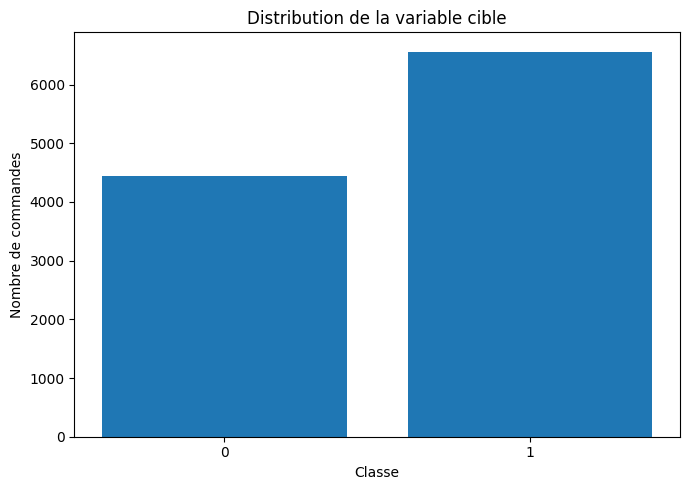

In [16]:
target_counts = df[TARGET].value_counts().sort_index()

plt.figure(figsize=(7, 5))

plt.bar(
    target_counts.index.astype(str),
    target_counts.values
)

plt.title("Distribution de la variable cible")
plt.xlabel("Classe")
plt.ylabel("Nombre de commandes")

plt.tight_layout()
plt.show()

Étudier les distributions des variables numériques

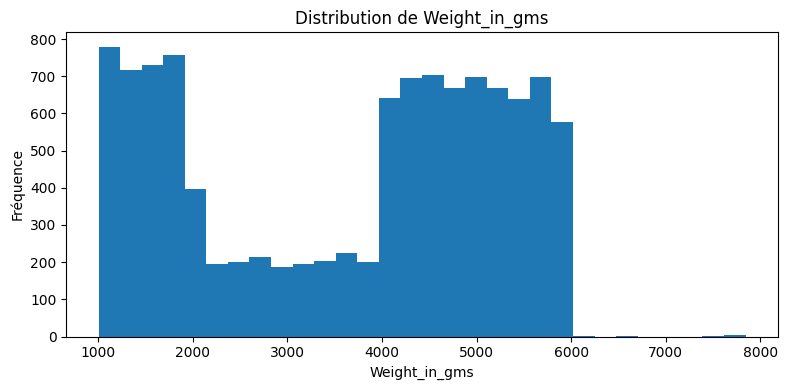

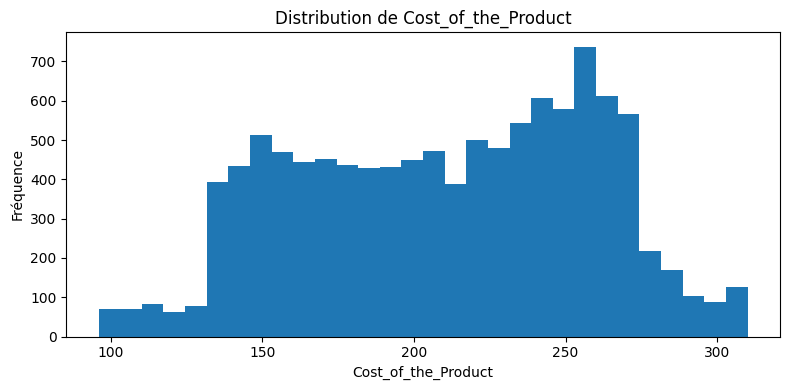

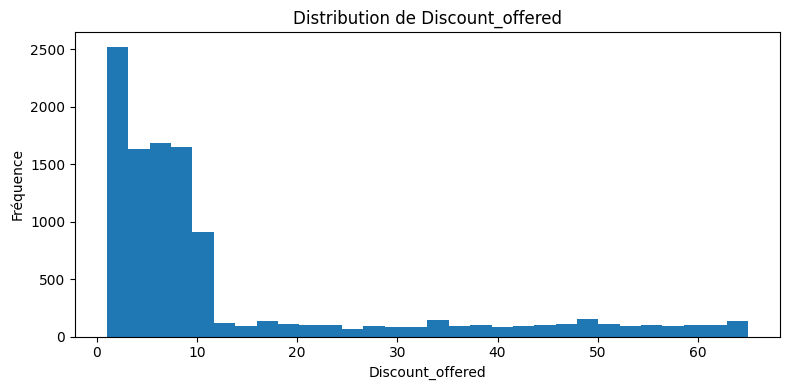

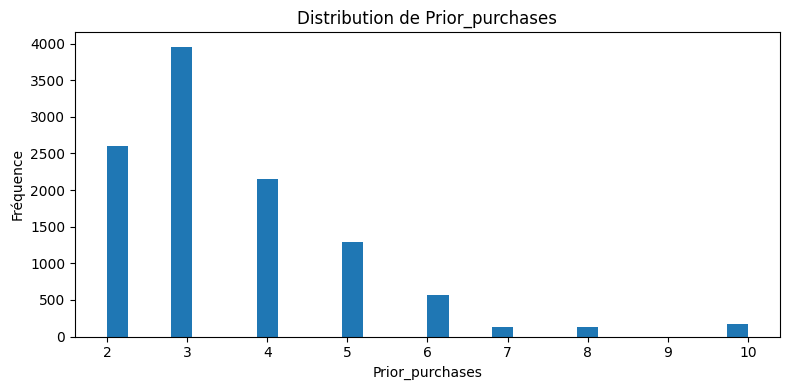

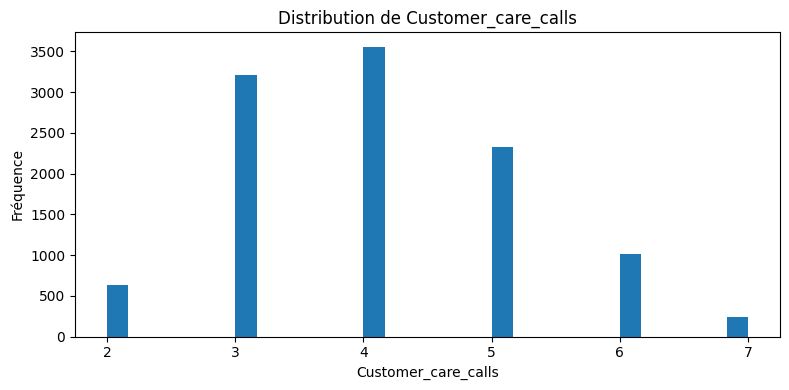

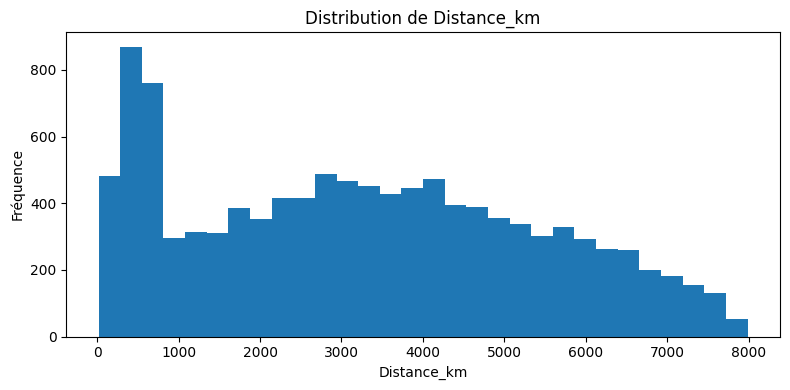

In [17]:
numeric_columns_to_plot = [
    "Weight_in_gms",
    "Cost_of_the_Product",
    "Discount_offered",
    "Prior_purchases",
    "Customer_care_calls",
    "Distance_km"
]

numeric_columns_to_plot = [
    col for col in numeric_columns_to_plot
    if col in df.columns
]

for column in numeric_columns_to_plot:

    plt.figure(figsize=(8, 4))

    plt.hist(
        pd.to_numeric(df[column], errors="coerce").dropna(),
        bins=30
    )

    plt.title(f"Distribution de {column}")
    plt.xlabel(column)
    plt.ylabel("Fréquence")

    plt.tight_layout()
    plt.show()

Répartition des modes d'expédition

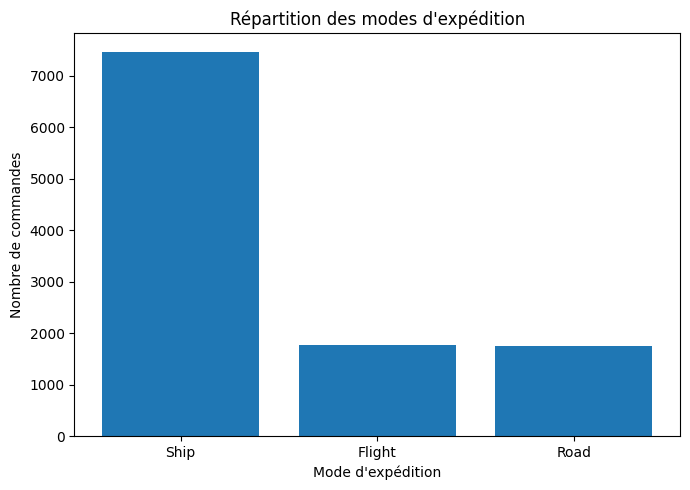

In [18]:
shipment_counts = df["Mode_of_Shipment"].value_counts()

plt.figure(figsize=(7, 5))

plt.bar(
    shipment_counts.index,
    shipment_counts.values
)

plt.title("Répartition des modes d'expédition")
plt.xlabel("Mode d'expédition")
plt.ylabel("Nombre de commandes")

plt.tight_layout()
plt.show()

Catégories de produits

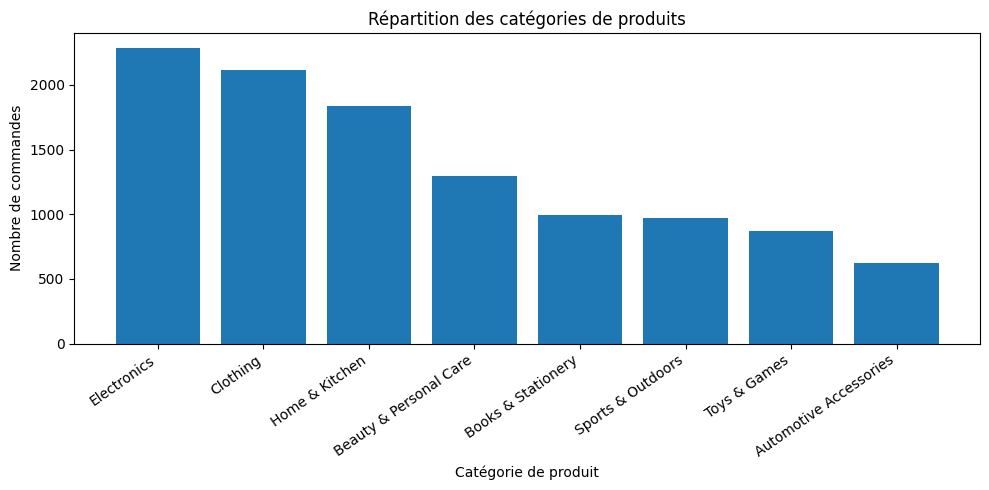

In [19]:
if "Product_Category" in df.columns:

    category_counts = df["Product_Category"].value_counts()

    plt.figure(figsize=(10, 5))

    plt.bar(
        category_counts.index,
        category_counts.values
    )

    plt.title("Répartition des catégories de produits")
    plt.xlabel("Catégorie de produit")
    plt.ylabel("Nombre de commandes")

    plt.xticks(rotation=35, ha="right")

    plt.tight_layout()
    plt.show()

Proportion de la classe 1 par mode d'expédition

In [20]:
shipment_target = pd.crosstab(
    df["Mode_of_Shipment"],
    df[TARGET],
    normalize="index"
) * 100

display(shipment_target.round(2))

Reached.on.Time_Y.N,0,1
Mode_of_Shipment,,
Flight,39.84,60.16
Road,41.19,58.81
Ship,40.24,59.76


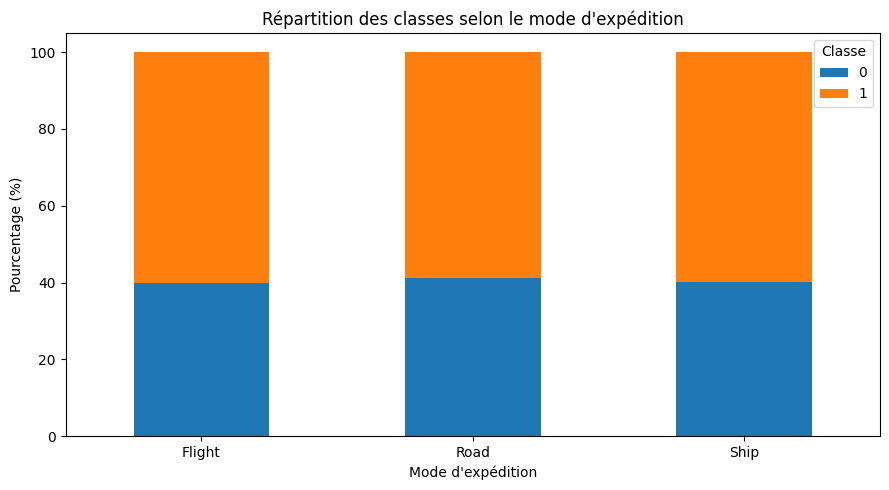

In [21]:
shipment_target.plot(
    kind="bar",
    stacked=True,
    figsize=(9, 5)
)

plt.title("Répartition des classes selon le mode d'expédition")
plt.xlabel("Mode d'expédition")
plt.ylabel("Pourcentage (%)")

plt.legend(title="Classe")

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Étudier les catégories de produits

Reached.on.Time_Y.N,0,1
Product_Category,,
Automotive Accessories,43.91,56.09
Beauty & Personal Care,38.86,61.14
Books & Stationery,40.32,59.68
Clothing,40.40,59.60
Electronics,38.81,61.19
Home & Kitchen,42.72,57.28
Sports & Outdoors,41.61,58.39
Toys & Games,37.34,62.66


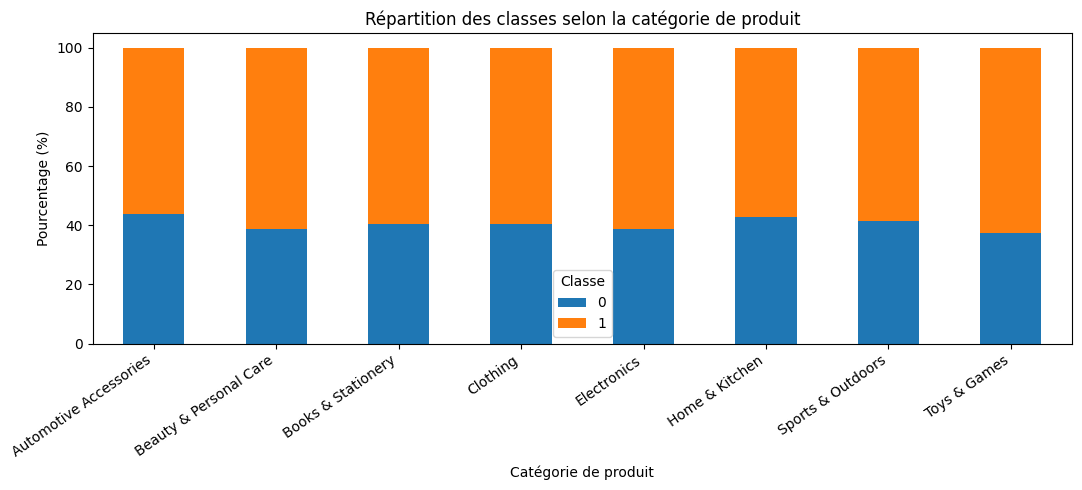

In [22]:
if "Product_Category" in df.columns:

    category_target = pd.crosstab(
        df["Product_Category"],
        df[TARGET],
        normalize="index"
    ) * 100

    display(category_target.round(2))

    category_target.plot(
        kind="bar",
        stacked=True,
        figsize=(11, 5)
    )

    plt.title("Répartition des classes selon la catégorie de produit")
    plt.xlabel("Catégorie de produit")
    plt.ylabel("Pourcentage (%)")

    plt.legend(title="Classe")
    plt.xticks(rotation=35, ha="right")

    plt.tight_layout()
    plt.show()